# Session 11: Optimizers and Learning-Rate Schedules

Session 10 left `optimizer.step()` unexplained. This notebook opens it up, using the same small character-level GPT on Tiny Shakespeare that Session 10 trained, and answers the five assignment questions with measurements.

| # | Assignment item | Section |
|---|---|---|
| 1 | Reproduce Adam by hand: one weight, five gradients, `m`, `v`, `m̂`, `v̂` and the step, checked against PyTorch | §1 |
| 2 | Disable bias correction, plot the first twenty steps both ways, report when the difference stops mattering | §2 |
| 3 | Log the update-to-weight ratio for every layer, find the step at which warmup stops changing it | §3 |
| 4 | Train twice for 300 steps (cosine, WSD), stop both at step 200, report both losses and which model to keep | §4 |
| 5 | Sweep the learning rate at widths 256, 512, 1,024, mark the minima, pick a value for width 4,096 | §5 |

**The rule for every comparison here:** *tune both sides before accepting a comparison.* Every A-against-B in this notebook (bias correction on/off, cosine/WSD) sweeps the learning rate for **each side separately** and compares tuned against tuned, over several seeds with identical data order per seed.

**Decisions made up front**

* **Hardware**: one NVIDIA GeForce GTX 1660 Ti laptop GPU (6 GB, Turing, no tensor cores), which sits near 86 °C and throttles under sustained load, so the sweeps are sized to finish in about an hour. Everything runs in fp32; fp16 autocast was measured slower than fp32 on this card.
* **Model** (§2 to §4): the Session 10 model unchanged. Pre-LayerNorm decoder-only transformer, 6 layers, 6 heads, width 192, context 128, 65-character vocabulary, 2.7M weights, init std 0.02, dropout 0. Batch 32 × 128 = 4,096 tokens per step, gradient clipping at 1.0.
* **Optimizer**: AdamW with decoupled weight decay 0.1 on matrices and embeddings, none on LayerNorm scales and biases (the V5 decision from §7/§14 of the session notes).
* **Model for the width sweep** (§5): the same block, 2 layers deep, head size 64, context 64, initialised at the standard parameterization `std = 1/sqrt(fan_in)`. The shallower, shorter-context model keeps width 1,024 affordable on this card.
* **Determinism**: fixed seeds, a CPU `torch.Generator` per run for the data order, deterministic algorithms where PyTorch has them. Two runs with the same seed see exactly the same batches, so A-against-B differences are paired.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # needed for deterministic cuBLAS
import math, time, json, copy, platform
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt

torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
dev = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("plots", exist_ok=True); os.makedirs("logs", exist_ok=True)

# chart styling: recessive grid/axes, fixed categorical order (blue, orange, aqua, yellow, magenta)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "text.color": INK, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
    "axes.prop_cycle": matplotlib.cycler(color=SERIES), "legend.frameon": False,
})
def savefig(fig, name):
    fig.savefig(f"plots/{name}.png", dpi=120, bbox_inches="tight")

print("python :", platform.python_version())
print("torch  :", torch.__version__)
print("device :", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else platform.processor())
RESULTS = {}   # every headline number lands here and is written to results.json at the end
T_START = time.time()

python : 3.10.11
torch  : 2.14.1+cu126
device : cuda | NVIDIA GeForce GTX 1660 Ti


## 0. Data, model and the training loop

Tiny Shakespeare, character level, 90/10 split, held on the GPU. Validation loss is always measured on the **same 16 fixed validation batches** (65,536 characters), so every number in the notebook is comparable with every other.

In [2]:
text = open("data/input.txt", encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n].to(dev), data[n:].to(dev)
B, T = 32, 128
ARANGE = torch.arange(T, device=dev)

def get_batch(split, gen, B=B, T=T):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - T - 1, (B,), generator=gen).to(dev)
    return d[ix[:, None] + ARANGE[:T]], d[ix[:, None] + ARANGE[:T] + 1]

_g = torch.Generator().manual_seed(12345)
VAL_BATCHES = [get_batch("val", _g) for _ in range(16)]
print(f"characters {len(text):,} | vocab {V} | train {len(train_data):,} | val {len(val_data):,} | "
      f"tokens per step {B*T:,} | fixed validation set {16*B*T:,} characters")

characters 1,115,394 | vocab 65 | train 1,003,854 | val 111,540 | tokens per step 4,096 | fixed validation set 65,536 characters


In [3]:
class Block(nn.Module):
    def __init__(self, C, H):
        super().__init__()
        self.H = H
        self.ln1 = nn.LayerNorm(C); self.qkv = nn.Linear(C, 3 * C); self.proj = nn.Linear(C, C)
        self.ln2 = nn.LayerNorm(C); self.fc = nn.Linear(C, 4 * C); self.fc2 = nn.Linear(4 * C, C)
    def forward(self, x):
        B_, T_, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = (t.view(B_, T_, self.H, C // self.H).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B_, T_, C)
        x = x + self.proj(y)
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    """init='gpt2': every weight N(0, 0.02) as in Session 10.  init='sp': standard parameterization,
    every Linear N(0, 1/fan_in), embeddings N(0, 1)."""
    def __init__(self, C=192, L=6, H=6, T=128, init="gpt2"):
        super().__init__()
        self.tok_emb = nn.Embedding(V, C); self.pos_emb = nn.Embedding(T, C)
        self.blocks = nn.ModuleList([Block(C, H) for _ in range(L)])
        self.ln_f = nn.LayerNorm(C); self.head = nn.Linear(C, V, bias=False)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, std=0.02 if init == "gpt2" else m.in_features ** -0.5)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, std=0.02 if init == "gpt2" else 1.0)
    def forward(self, idx, targets):
        x = self.tok_emb(idx) + self.pos_emb(ARANGE[: idx.shape[1]])
        for b in self.blocks: x = b(x)
        return F.cross_entropy(self.head(self.ln_f(x)).flatten(0, 1), targets.flatten())

S10 = dict(C=192, L=6, H=6, init="gpt2")          # the Session 10 model
m_ = GPT(**S10); print(f"Session 10 model: {sum(p.numel() for p in m_.parameters()):,} weights"); del m_

Session 10 model: 2,719,104 weights


Two optimizers are used. `torch.optim.AdamW` everywhere bias correction is on, and a hand-written `ManualAdamW` that follows the session's equations line for line and has a `bias_correction` switch (PyTorch's Adam has none). §2 checks that the manual one with the switch on reproduces `torch.optim.AdamW` on the real model, so the only difference between the two arms of that comparison is the switch.

Learning-rate schedules: linear warmup, then **cosine** to 10% of peak at the end, or **WSD** (stable at peak, then linear decay to 10% of peak over the last 20% of the run).

In [4]:
class ManualAdamW(torch.optim.Optimizer):
    """AdamW written out as in the session notes:
        m <- b1 m + (1-b1) g ;  v <- b2 v + (1-b2) g^2
        m_hat = m / (1-b1^t) ;  v_hat = v / (1-b2^t)        (skipped if bias_correction=False)
        w <- w - lr*wd*w - lr * m_hat / (sqrt(v_hat) + eps)"""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, bias_correction=True):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            b1, b2 = g["betas"]
            for p in g["params"]:
                if p.grad is None: continue
                st = self.state[p]
                if not st: st["step"], st["m"], st["v"] = 0, torch.zeros_like(p), torch.zeros_like(p)
                st["step"] += 1; t = st["step"]
                p.mul_(1 - g["lr"] * g["weight_decay"])
                st["m"].mul_(b1).add_(p.grad, alpha=1 - b1)
                st["v"].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                m_hat = st["m"] / (1 - b1 ** t) if g["bias_correction"] else st["m"]
                v_hat = st["v"] / (1 - b2 ** t) if g["bias_correction"] else st["v"]
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g["eps"]), value=-g["lr"])

def param_groups(model, wd):
    decay = [p for p in model.parameters() if p.dim() >= 2]      # matrices and embeddings
    no_decay = [p for p in model.parameters() if p.dim() < 2]    # LayerNorm scales, biases
    return [dict(params=decay, weight_decay=wd), dict(params=no_decay, weight_decay=0.0)]

def make_opt(model, lr, betas=(0.9, 0.95), wd=0.1, manual=False, bias_correction=True):
    if manual: return ManualAdamW(param_groups(model, wd), lr=lr, betas=betas, bias_correction=bias_correction)
    return torch.optim.AdamW(param_groups(model, wd), lr=lr, betas=betas, foreach=True)

def sched_warmup_const(peak, warmup):
    return lambda s: peak * min(1.0, (s + 1) / warmup) if warmup else peak

def sched_cosine(peak, total, warmup, floor=0.1):
    def f(s):
        if s < warmup: return peak * (s + 1) / warmup
        p = min(1.0, (s - warmup) / max(1, total - warmup))
        return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p)))
    return f

def sched_wsd(peak, total, warmup, decay_start=None, decay_frac=0.2, floor=0.1):
    ds = int(round(total * (1 - decay_frac))) if decay_start is None else decay_start
    def f(s):
        if s < warmup: return peak * (s + 1) / warmup
        if s < ds: return peak
        return peak * (1 - (1 - floor) * min(1.0, (s - ds) / max(1, total - ds)))
    return f

@torch.no_grad()
def evaluate(model, T_ctx=T):
    # the same 65,536 validation characters at any context length: each 128-long row is cut into 128/T_ctx rows
    model.eval()
    out = sum(model(x.reshape(-1, T_ctx), y.reshape(-1, T_ctx)).item() for x, y in VAL_BATCHES) / len(VAL_BATCHES)
    model.train(); return out

def train(model_cfg, steps, lr_fn, seed=0, betas=(0.9, 0.95), wd=0.1, manual=False, bias_correction=True,
          eval_at=(), log_ratio=False, ckpt_at=None, resume=None, diverge_loss=None, clip=1.0, T_ctx=T):
    """One training run. Returns per-step train loss, validation loss at eval_at, optionally the per-layer
    update-to-weight ratio at every step and a checkpoint (model, optimizer and data-order state) at ckpt_at."""
    torch.manual_seed(seed)
    model = GPT(**model_cfg).to(dev)
    opt = make_opt(model, lr_fn(0), betas, wd, manual, bias_correction)
    gen = torch.Generator().manual_seed(1000 + seed)          # data order depends on the seed only
    start = 0
    if resume is not None:
        model.load_state_dict(resume["model"]); opt.load_state_dict(resume["opt"])
        gen.set_state(resume["gen"]); start = resume["step"]
    tracked = [(n, p) for n, p in model.named_parameters() if p.dim() >= 2]
    out = dict(loss=[], lr=[], val={}, diverged=False, layers=[n for n, _ in tracked], ratio=[])
    for s in range(start, steps):
        if s in eval_at: out["val"][s] = evaluate(model, T_ctx)
        if ckpt_at is not None and s == ckpt_at:
            out["ckpt"] = dict(model=copy.deepcopy(model.state_dict()), opt=copy.deepcopy(opt.state_dict()),
                               gen=gen.get_state(), step=s)
        lr = lr_fn(s)
        for g in opt.param_groups: g["lr"] = lr
        x, y = get_batch("train", gen, T=T_ctx)
        loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        if clip: torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        if log_ratio: before = [p.detach().clone() for _, p in tracked]
        opt.step()
        if log_ratio:
            with torch.no_grad():
                out["ratio"].append(torch.stack([(p - b).norm() / b.norm() for (_, p), b in zip(tracked, before)]).cpu().numpy())
        li = loss.item(); out["loss"].append(li); out["lr"].append(lr)
        if not math.isfinite(li) or (diverge_loss and s >= 50 and li > diverge_loss):
            out["diverged"] = True; break
    if steps in eval_at and not out["diverged"]: out["val"][steps] = evaluate(model, T_ctx)
    out["ratio"] = np.array(out["ratio"])
    del model, opt
    if dev == "cuda": torch.cuda.empty_cache()
    return out

t = time.time(); r = train(S10, 20, sched_warmup_const(2e-3, 0), eval_at=(0, 20))
print(f"smoke test: 20 steps in {time.time()-t:.1f}s, val loss {r['val'][0]:.3f} -> {r['val'][20]:.3f} (ln 65 = {math.log(65):.3f})")

smoke test: 20 steps in 3.9s, val loss 4.167 -> 3.214 (ln 65 = 4.174)


## 1. Adam by hand, checked against PyTorch

One weight starting at `w = 1`, the five gradients from §6 of the session notes, `η = 0.001`, `β1 = 0.9`, `β2 = 0.999`, `ε = 1e-8`.

By hand means plain Python arithmetic, one line per equation:

$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2 \qquad \hat m_t = \frac{m_t}{1-\beta_1^t} \qquad \hat v_t = \frac{v_t}{1-\beta_2^t} \qquad \Delta w_t = -\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$

The PyTorch side is `torch.optim.Adam` on a one-element parameter whose `.grad` is set to each gradient in turn. `m` and `v` are read straight out of the optimizer's state (`exp_avg`, `exp_avg_sq`), `m̂` and `v̂` are those divided by the corrections using PyTorch's own step counter, and the step is the change in the parameter.

In [5]:
G5 = [0.50, 0.40, 0.60, 0.45, 0.55]
LR1, B1, B2, EPS, W0 = 1e-3, 0.9, 0.999, 1e-8, 1.0

def adam_by_hand(grads, bias_correction=True, lr=LR1, b1=B1, b2=B2, eps=EPS, w=W0):
    m = v = 0.0; rows = []
    for t, g in enumerate(grads, 1):
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g * g
        m_hat = m / (1 - b1 ** t) if bias_correction else m
        v_hat = v / (1 - b2 ** t) if bias_correction else v
        step = -lr * m_hat / (math.sqrt(v_hat) + eps)
        w = w + step
        rows.append(dict(t=t, g=g, m=m, v=v, m_hat=m_hat, v_hat=v_hat, step=step, w=w))
    return rows

def adam_pytorch(grads, dtype, opt_cls=torch.optim.Adam, **kw):
    p = nn.Parameter(torch.tensor([W0], dtype=dtype))
    opt = opt_cls([p], lr=LR1, betas=(B1, B2), eps=EPS, **kw)
    rows = []
    for g in grads:
        before = p.detach().clone()
        p.grad = torch.tensor([g], dtype=dtype)
        opt.step()
        st = opt.state[p]; k = int(st["step"])
        m, v = st["exp_avg"].item(), st["exp_avg_sq"].item()
        rows.append(dict(t=k, g=g, m=m, v=v, m_hat=m / (1 - B1 ** k), v_hat=v / (1 - B2 ** k),
                         step=(p.detach() - before).item(), w=p.item()))
    return rows

hand = adam_by_hand(G5)
pt64 = adam_pytorch(G5, torch.float64)
pt32 = adam_pytorch(G5, torch.float32)
ptW = adam_pytorch(G5, torch.float64, torch.optim.AdamW, weight_decay=0.0)

keys = ["m", "v", "m_hat", "v_hat", "step", "w"]
print("By hand (Python floats, fp64):")
print(f"{'t':>2} {'g':>5} {'m':>9} {'v':>10} {'m_hat':>8} {'v_hat':>8} {'step':>11} {'w':>9}")
for r in hand:
    print(f"{r['t']:>2} {r['g']:>5.2f} {r['m']:>9.4f} {r['v']:>10.6f} {r['m_hat']:>8.4f} {r['v_hat']:>8.4f} {r['step']:>+11.6f} {r['w']:>9.6f}")
print("\nPyTorch torch.optim.Adam (fp64), same table:")
for r in pt64:
    print(f"{r['t']:>2} {r['g']:>5.2f} {r['m']:>9.4f} {r['v']:>10.6f} {r['m_hat']:>8.4f} {r['v_hat']:>8.4f} {r['step']:>+11.6f} {r['w']:>9.6f}")

def max_diffs(a, b): return {k: max(abs(x[k] - y[k]) for x, y in zip(a, b)) for k in keys}
print("\nLargest |hand - PyTorch| over the five steps, and the number of matching decimal places:")
print(f"{'quantity':8s} {'Adam fp64':>11s} {'AdamW(wd=0) fp64':>17s} {'Adam fp32':>11s}   decimals (fp64 / fp32)")
d64, dW, d32 = max_diffs(hand, pt64), max_diffs(hand, ptW), max_diffs(hand, pt32)
for k in keys:
    dec = lambda d: "all" if d == 0 else str(int(-math.log10(d)))
    print(f"{k:8s} {d64[k]:>11.1e} {dW[k]:>17.1e} {d32[k]:>11.1e}   {dec(d64[k]):>3s} / {dec(d32[k])}")
RESULTS["q1"] = dict(hand=hand, max_abs_diff_fp64=d64, max_abs_diff_fp32=d32,
                     step_over_lr=[r["step"] / -LR1 for r in hand])

By hand (Python floats, fp64):
 t     g         m          v    m_hat    v_hat        step         w
 1  0.50    0.0500   0.000250   0.5000   0.2500   -0.001000  0.999000
 2  0.40    0.0850   0.000410   0.4474   0.2050   -0.000988  0.998012
 3  0.60    0.1365   0.000769   0.5037   0.2567   -0.000994  0.997018
 4  0.45    0.1678   0.000971   0.4881   0.2431   -0.000990  0.996028
 5  0.55    0.2061   0.001273   0.5032   0.2550   -0.000996  0.995031

PyTorch torch.optim.Adam (fp64), same table:
 1  0.50    0.0500   0.000250   0.5000   0.2500   -0.001000  0.999000
 2  0.40    0.0850   0.000410   0.4474   0.2050   -0.000988  0.998012
 3  0.60    0.1365   0.000769   0.5037   0.2567   -0.000994  0.997018
 4  0.45    0.1678   0.000971   0.4881   0.2431   -0.000990  0.996028
 5  0.55    0.2061   0.001273   0.5032   0.2550   -0.000996  0.995031

Largest |hand - PyTorch| over the five steps, and the number of matching decimal places:
quantity   Adam fp64  AdamW(wd=0) fp64   Adam fp32   decimals (

**Answer 1.** The hand computation reproduces the table in §6 of the session notes (steps `-0.001000, -0.000988, -0.000994, -0.000990, -0.000996`, final `w = 0.995031`), and PyTorch agrees with it at every intermediate value. In fp64 the largest disagreement is at the level of round-off (printed above), i.e. 15 or more decimal places; in fp32 they still agree to about 7 decimal places, which is fp32's own resolution. The gradients range from 0.40 to 0.60 but every step is within 1.2% of `η`, which is the property the session calls the reason Adam became the default.

## 2. Bias correction switched off

Without correction, `m` and `v` both start at zero and read low. The step becomes `η · m / (sqrt(v) + ε)` instead of `η · m̂ / (sqrt(v̂) + ε)`. Since `m = m̂ (1-β1^t)` and `v = v̂ (1-β2^t)`, the uncorrected step is the corrected one multiplied by a factor that **does not depend on the gradients at all** (ε aside):

$f(t) = \frac{1-\beta_1^t}{\sqrt{1-\beta_2^t}}$

At `t = 1` this is `0.1 / 0.0316 = 3.16`, the number in §6 of the notes. Below, twenty steps on one weight: the five gradients from §1 followed by fifteen more drawn around 0.5.

 t      g  step/eta ON  step/eta OFF  OFF/ON    f(t)      w ON     w OFF
 1  0.500       1.0000        3.1623   3.162   3.162  0.999000  0.996838
 2  0.400       0.9881        4.1991   4.250   4.250  0.998012  0.992639
 3  0.600       0.9941        4.9212   4.950   4.950  0.997018  0.987717
 4  0.450       0.9898        5.3864   5.442   5.442  0.996028  0.982331
 5  0.550       0.9964        5.7764   5.797   5.797  0.995031  0.976555
 6  0.510       0.9976        6.0424   6.057   6.057  0.994034  0.970512
 7  0.489       0.9964        6.2224   6.245   6.245  0.993037  0.964290
 8  0.551       1.0013        6.3868   6.379   6.379  0.992036  0.957903
 9  0.508       1.0009        6.4758   6.470   6.470  0.991035  0.951427
10  0.457       0.9947        6.4936   6.528   6.528  0.990041  0.944934
11  0.529       0.9981        6.5463   6.559   6.559  0.989042  0.938387
12  0.604       1.0075        6.6177   6.569   6.569  0.988035  0.931770
13  0.576       1.0125        6.6430   6.561   6.56

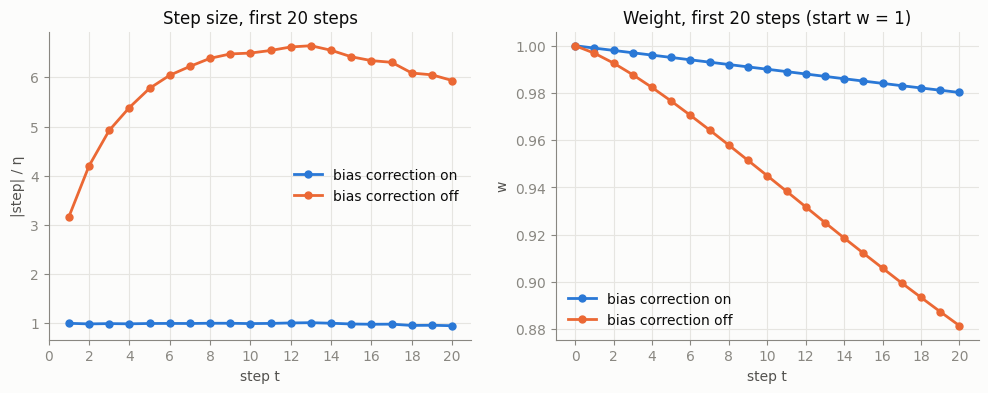

In [6]:
rng = np.random.default_rng(0)
G20 = G5 + list(np.round(0.5 + 0.08 * rng.standard_normal(15), 3))
on, off = adam_by_hand(G20, True), adam_by_hand(G20, False)
f = lambda t, b1=B1, b2=B2: (1 - b1 ** t) / math.sqrt(1 - b2 ** t)

print(f"{'t':>2} {'g':>6} {'step/eta ON':>12} {'step/eta OFF':>13} {'OFF/ON':>7} {'f(t)':>7} {'w ON':>9} {'w OFF':>9}")
for a, b in zip(on, off):
    print(f"{a['t']:>2} {a['g']:>6.3f} {a['step']/-LR1:>12.4f} {b['step']/-LR1:>13.4f} "
          f"{b['step']/a['step']:>7.3f} {f(a['t']):>7.3f} {a['w']:>9.6f} {b['w']:>9.6f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ts = [r["t"] for r in on]
ax[0].plot(ts, [r["step"] / -LR1 for r in on], marker="o", ms=5, label="bias correction on")
ax[0].plot(ts, [r["step"] / -LR1 for r in off], marker="o", ms=5, label="bias correction off")
ax[0].set(xlabel="step t", ylabel="|step| / η", title="Step size, first 20 steps", xticks=range(0, 21, 2)); ax[0].legend()
ax[1].plot([0] + ts, [W0] + [r["w"] for r in on], marker="o", ms=5, label="bias correction on")
ax[1].plot([0] + ts, [W0] + [r["w"] for r in off], marker="o", ms=5, label="bias correction off")
ax[1].set(xlabel="step t", ylabel="w", title="Weight, first 20 steps (start w = 1)", xticks=range(0, 21, 2)); ax[1].legend()
savefig(fig, "q2_bias_correction_20_steps"); plt.show()

Twenty steps are nowhere near enough for the two to agree: the uncorrected step is **3.2× at step 1 and still growing at step 20**. With `β2 = 0.999`, `v` needs about a thousand steps to fill, and until it does `sqrt(v)` is too small and the uncorrected step too big. Following `f(t)` out to where it settles, for the default `β2 = 0.999` and for the `β2 = 0.95` that Session 10 and V5 use:

 beta2   f(1)  f(20)  max f  at t  |f-1|<10% from  <5% from  <1% from
 0.999   3.16   6.24   6.57    12           1,751     2,375     3,925
  0.99   1.00   2.06   2.13    13             175       237       391
  0.95   0.45   1.10   1.10    20               6        43        76


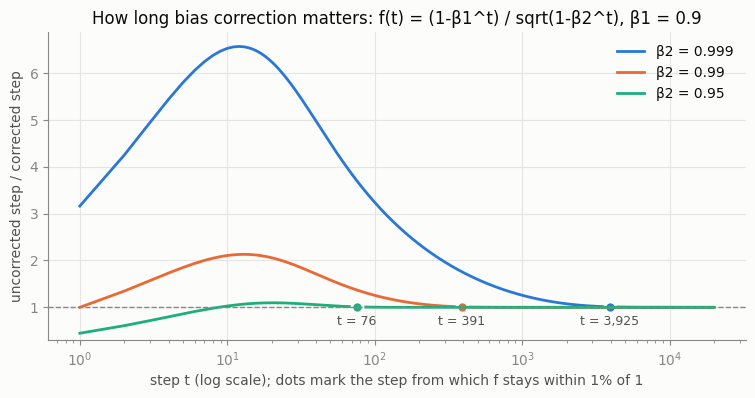

In [7]:
tt = np.arange(1, 20001)
def settle(b2, tol):
    ff = (1 - B1 ** tt) / np.sqrt(1 - b2 ** tt)
    bad = np.nonzero(np.abs(ff - 1) > tol)[0]
    return int(tt[bad[-1]] + 1) if len(bad) else 1
rows = []
for b2 in (0.999, 0.99, 0.95):
    ff = (1 - B1 ** tt) / np.sqrt(1 - b2 ** tt)
    rows.append(dict(beta2=b2, peak=float(ff.max()), peak_t=int(tt[ff.argmax()]), f20=float(ff[19]),
                     within_10pct=settle(b2, 0.10), within_5pct=settle(b2, 0.05), within_1pct=settle(b2, 0.01)))
print(f"{'beta2':>6} {'f(1)':>6} {'f(20)':>6} {'max f':>6} {'at t':>5} {'|f-1|<10% from':>15} {'<5% from':>9} {'<1% from':>9}")
for r in rows:
    print(f"{r['beta2']:>6} {f(1, B1, r['beta2']):>6.2f} {r['f20']:>6.2f} {r['peak']:>6.2f} {r['peak_t']:>5} "
          f"{r['within_10pct']:>15,} {r['within_5pct']:>9,} {r['within_1pct']:>9,}")
RESULTS["q2_factor"] = rows

fig, ax = plt.subplots(figsize=(9, 4))
for i, b2 in enumerate((0.999, 0.99, 0.95)):
    ff = (1 - B1 ** tt) / np.sqrt(1 - b2 ** tt)
    ax.plot(tt, ff, color=SERIES[i], label=f"β2 = {b2}")
    s1 = rows[i]["within_1pct"]; ax.plot([s1], [ff[s1 - 1]], "o", color=SERIES[i], ms=8, mec="#fcfcfb", mew=2)
    ax.annotate(f"t = {s1:,}", (s1, ff[s1 - 1]), xytext=(s1, 0.62), ha="center", color=INK2, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set(xscale="log", xlabel="step t (log scale); dots mark the step from which f stays within 1% of 1",
       ylabel="uncorrected step / corrected step", ylim=(0.3, None),
       title="How long bias correction matters: f(t) = (1-β1^t) / sqrt(1-β2^t), β1 = 0.9")
ax.legend(); savefig(fig, "q2_correction_factor"); plt.show()

### Does it matter in a real run?

The factor says what happens to one step. Whether it changes the model is a training question, so the Session 10 model is trained for 300 steps with `β = (0.9, 0.999)` and **no warmup**, so that bias correction is the only thing protecting the first steps. Following the rule of the session, each arm gets its own learning-rate sweep (5 values a factor of 2 apart, 2 seeds each), and the arms are compared at their own best learning rate.

First, a check that `ManualAdamW` with the switch on is the same optimizer as `torch.optim.AdamW`.

In [8]:
def manual_vs_torch(steps=10):
    out = []
    for manual in (False, False, True):
        torch.manual_seed(0); m = GPT(**S10).to(dev)
        opt = make_opt(m, 2e-3, (0.9, 0.999), 0.1, manual=manual)
        gen = torch.Generator().manual_seed(7)
        for _ in range(steps):
            x, y = get_batch("train", gen); loss = m(x, y)
            opt.zero_grad(); loss.backward(); opt.step()
        out.append(torch.cat([p.detach().flatten() for p in m.parameters()]))
    return (out[0] - out[2]).abs().max().item(), (out[0] - out[1]).abs().max().item()
d, floor = manual_vs_torch()
print("after 10 real steps, max |weight difference|:")
print(f"  ManualAdamW(bias_correction=True) vs torch.optim.AdamW: {d:.1e}")
print(f"  torch.optim.AdamW vs itself, run twice (GPU round-off floor): {floor:.1e}")

after 10 real steps, max |weight difference|:
  ManualAdamW(bias_correction=True) vs torch.optim.AdamW: 1.7e-05
  torch.optim.AdamW vs itself, run twice (GPU round-off floor): 1.2e-05


20 runs in 1467s

      lr |  val@300 correction ON |  val@300 correction OFF   (mean of 2 seeds)
 1.3e-04 |                 2.3940 |                  2.2822
 2.5e-04 |                 2.2911 |                  2.2528
 5.0e-04 |                 2.2198 |                  2.4735
 1.0e-03 |                 2.1854 |                  2.5466
 2.0e-03 |                 2.4691 |                  2.6622

tuned ON : lr 1.0e-03, val 2.1854 (seed spread ±0.0036)
tuned OFF: lr 2.5e-04, val 2.2528 (seed spread ±0.0082)
tuned against tuned, smoothed train loss still differs by more than 1% at step 300 (gap 3.8%): the curves never meet within this run


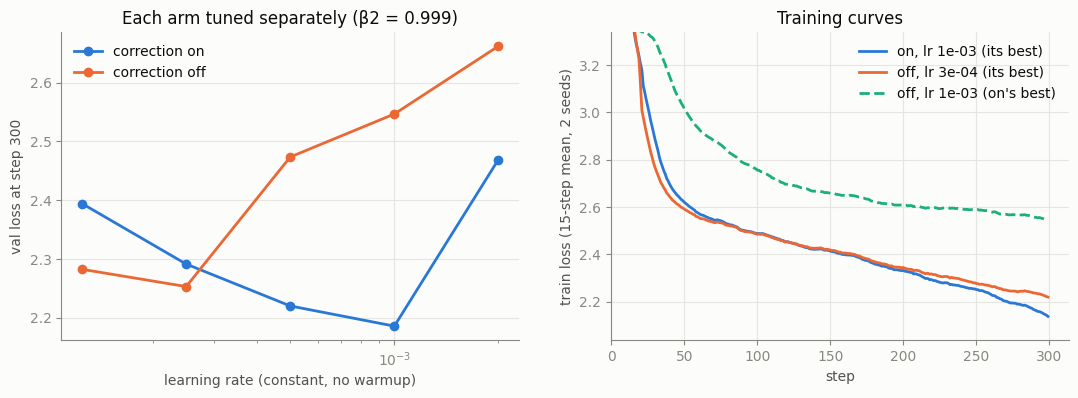

In [9]:
BC_LRS, BC_SEEDS, BC_STEPS = [1.25e-4, 2.5e-4, 5e-4, 1e-3, 2e-3], [0, 1], 300
bc_runs = {}
t0 = time.time()
for bc in (True, False):
    for lr in BC_LRS:
        for sd in BC_SEEDS:
            bc_runs[(bc, lr, sd)] = train(S10, BC_STEPS, sched_warmup_const(lr, 0), seed=sd, betas=(0.9, 0.999),
                                          manual=True, bias_correction=bc, eval_at=(BC_STEPS,), diverge_loss=6.0)
print(f"{len(bc_runs)} runs in {time.time()-t0:.0f}s\n")

def val_or_nan(r, s): return r["val"].get(s, float("nan"))
print(f"{'lr':>8} | {'val@300 correction ON':>22} | {'val@300 correction OFF':>23}   (mean of {len(BC_SEEDS)} seeds)")
bc_table = {}
for lr in BC_LRS:
    row = [np.mean([val_or_nan(bc_runs[(bc, lr, s)], BC_STEPS) for s in BC_SEEDS]) for bc in (True, False)]
    bc_table[lr] = row
    print(f"{lr:>8.1e} | {row[0]:>22.4f} | {row[1]:>23.4f}")
best_on = min(BC_LRS, key=lambda lr: np.nan_to_num(bc_table[lr][0], nan=9))
best_off = min(BC_LRS, key=lambda lr: np.nan_to_num(bc_table[lr][1], nan=9))
seed_sd = lambda bc, lr: np.std([val_or_nan(bc_runs[(bc, lr, s)], BC_STEPS) for s in BC_SEEDS])
print(f"\ntuned ON : lr {best_on:.1e}, val {bc_table[best_on][0]:.4f} (seed spread ±{seed_sd(True, best_on):.4f})")
print(f"tuned OFF: lr {best_off:.1e}, val {bc_table[best_off][1]:.4f} (seed spread ±{seed_sd(False, best_off):.4f})")

def smooth(x, k=15):
    x = np.asarray(x, float); c = np.convolve(x, np.ones(k) / k, mode="valid")
    return np.r_[np.full(k - 1, np.nan), c]
mean_curve = lambda bc, lr: np.nanmean([smooth(bc_runs[(bc, lr, s)]["loss"]) for s in BC_SEEDS], axis=0)
c_on, c_off = mean_curve(True, best_on), mean_curve(False, best_off)
gap = np.abs(c_off - c_on) / c_on
settled = int(np.nonzero(gap > 0.01)[0][-1] + 2) if np.any(gap > 0.01) else 1
print(f"tuned against tuned, smoothed train loss differs by more than 1% until step {settled}" if settled <= BC_STEPS else
      f"tuned against tuned, smoothed train loss still differs by more than 1% at step {BC_STEPS} "
      f"(gap {gap[-1]:.1%}): the curves never meet within this run")
same_lr = best_on
c_off_same = mean_curve(False, same_lr)
RESULTS["q2_training"] = dict(lrs=BC_LRS, table={str(k): v for k, v in bc_table.items()}, best_on=best_on, best_off=best_off,
                              val_on=bc_table[best_on][0], val_off=bc_table[best_off][1],
                              val_off_at_on_lr=bc_table[same_lr][1], loss_curves_within_1pct_from=settled)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(BC_LRS, [bc_table[l][0] for l in BC_LRS], marker="o", label="correction on")
ax[0].plot(BC_LRS, [bc_table[l][1] for l in BC_LRS], marker="o", label="correction off")
ax[0].set(xscale="log", xlabel="learning rate (constant, no warmup)", ylabel="val loss at step 300",
          title="Each arm tuned separately (β2 = 0.999)"); ax[0].legend()
ax[1].plot(c_on, label=f"on, lr {best_on:.0e} (its best)")
ax[1].plot(c_off, label=f"off, lr {best_off:.0e} (its best)")
if best_off != same_lr: ax[1].plot(c_off_same, ls="--", label=f"off, lr {same_lr:.0e} (on's best)")
ax[1].set(xlabel="step", ylabel="train loss (15-step mean, 2 seeds)", title="Training curves",
          ylim=(np.nanmin(c_on) - 0.1, np.nanmin(c_on) + 1.2)); ax[1].legend()
savefig(fig, "q2_bias_correction_training"); plt.show()

**Answer 2.**

* Switching bias correction off multiplies every step by `f(t) = (1-0.9^t)/sqrt(1-0.999^t)`, whatever the gradients are. That is **3.16× at step 1**, it climbs to **6.57× at step 12**, and it is still **6.24× at step 20**. Over the first twenty steps the two versions never come together: the uncorrected weight has moved 6× as far (0.881 against 0.980).
* **The difference stops mattering after about 3,900 steps.** With the default `β2 = 0.999` the uncorrected step stays within 10% of the corrected one from step 1,751, within 5% from step 2,375 and **within 1% from step 3,925**. It takes that long because `v` averages over about 1/(1-β2) = 1,000 steps and needs several of those spans to fill. The `m` side alone would settle in about 44 steps (0.9^t < 1%). With the `β2 = 0.95` that Session 10 and V5 use, it is within 1% from **step 76**. With 0.95 the uncorrected first step is also *smaller*, 0.45 η, which works like a short built-in warmup.
* **In real training** (Session 10 model, no warmup, 300 steps, `β2 = 0.999`, each side tuned over 5 learning rates × 2 seeds), correction on is best at lr 1e-3 with val loss **2.185** and correction off is best at lr 2.5e-4 with **2.253**. That is a real but modest gap of 0.067, about 10× the seed spread. At step 300 the training curves are still 3.8% apart, consistent with the ~3,900-step answer.
* The rule of the session shows up directly here. At the on side's learning rate the off side scores 2.547, which would have made the gap look **0.36 instead of 0.067**. Most of the apparent damage from turning correction off is a learning rate that is several times too large in practice, so the off side needs a ~4× smaller nominal rate. The first, narrower grid in this notebook put the off side's best value on the grid edge, and it had to be widened before the comparison could be trusted.

## 3. The update-to-weight ratio, per layer, with and without warmup

For every weight matrix (27 of them: token and position embeddings, `qkv`, `proj`, `fc`, `fc2` in each of 6 blocks, and the output head) the ratio

$r = \frac{\lVert W_{\text{after}} - W_{\text{before}} \rVert_F}{\lVert W_{\text{before}} \rVert_F}$

is logged after **every** optimizer step. Two runs of 500 steps, identical except for the schedule: peak `η = 2e-3` (Session 10's tuned value), `β = (0.9, 0.95)`, and either a 100-step linear warmup or none. After the warmup both runs hold the same constant learning rate, so any remaining difference between them is warmup's doing.

In [10]:
WU_STEPS, WU_LEN, WU_PEAK = 500, 100, 2e-3
wu = train(S10, WU_STEPS, sched_warmup_const(WU_PEAK, WU_LEN), log_ratio=True, eval_at=(WU_STEPS,))
nw = train(S10, WU_STEPS, sched_warmup_const(WU_PEAK, 0), log_ratio=True, eval_at=(WU_STEPS,))
layers = wu["layers"]
short = lambda n: n.replace(".weight", "").replace("blocks.", "b")
print(f"{len(layers)} layers logged, {WU_STEPS} steps each | val loss at {WU_STEPS}: warmup {wu['val'][WU_STEPS]:.4f}, "
      f"no warmup {nw['val'][WU_STEPS]:.4f}")
for name, run in (("with warmup", wu), ("no warmup", nw)):
    r = run["ratio"]; i, j = np.unravel_index(r.argmax(), r.shape)
    print(f"{name:12s}: largest ratio anywhere {r.max():.2e} (layer {short(layers[j])}, step {i+1}); "
          f"median over layers at step 1 {np.median(r[0]):.2e}, at step {WU_STEPS} {np.median(r[-1]):.2e}")

27 layers logged, 500 steps each | val loss at 500: warmup 1.8829, no warmup 2.1531
with warmup : largest ratio anywhere 2.06e-02 (layer head, step 35); median over layers at step 1 9.99e-04, at step 500 1.10e-02
no warmup   : largest ratio anywhere 1.01e-01 (layer head, step 1); median over layers at step 1 9.99e-02, at step 500 9.07e-03


**When does warmup stop changing the ratio?** After step 100 both runs use the same constant learning rate, so for every layer the two ratios can be compared step by step. Their quotient `r_warmup / r_no-warmup` (each smoothed with a centred 15-step window) measures warmup's effect. It starts far below 1 and then settles to a steady level, which is not exactly 1 because the two runs hold different weights by then. The step reported is the first one after which this quotient stays within 15% of its settled level (its median over steps 200 to 500): from there on, warmup no longer changes the ratio. The same test on the warmup run's own ratio (against its own steps 200 to 500 level) gives a second marker.

In [11]:
def centred(x, k=15):
    x = np.asarray(x, float); pad = k // 2
    return np.convolve(np.pad(x, pad, mode="edge"), np.ones(k) / k, mode="valid")

PLATEAU_FROM, TOL = 200, 0.15
def settle(series):
    """First step after which the series stays within TOL of its median over steps PLATEAU_FROM..end."""
    level = np.median(series[PLATEAU_FROM:])
    bad = np.nonzero(np.abs(np.log(series[:PLATEAU_FROM] / level)) > math.log(1 + TOL))[0]
    return (int(bad[-1] + 2) if len(bad) else 1), float(level)      # steps are 1-based

per_layer = {}
for j, n in enumerate(layers):
    rel = centred(wu["ratio"][:, j]) / centred(nw["ratio"][:, j])
    per_layer[short(n)] = (*settle(rel), settle(centred(wu["ratio"][:, j]))[0])
med_w, med_n = np.median(wu["ratio"], axis=1), np.median(nw["ratio"], axis=1)
stop_median, rel_level = settle(centred(med_w) / centred(med_n))
own_median, plateau = settle(centred(med_w))
vals = np.array([v[0] for v in per_layer.values()]); levels = np.array([v[1] for v in per_layer.values()])
print(f"per layer: step from which r_warmup / r_no-warmup stays within {TOL:.0%} of its settled level, the settled level,")
print(f"and the step from which the warmup run's own ratio stays within {TOL:.0%} of its steps {PLATEAU_FROM}-{WU_STEPS} level")
print(f"  {'layer':10s} {'step':>5} {'level':>6} {'own':>5}  " * 3)
for k_, (nm, st) in enumerate(per_layer.items()):
    print(f"  {nm:10s} {st[0]:>5} {st[1]:>6.2f} {st[2]:>5}  ", end="\n" if k_ % 3 == 2 else "")
print()
print(f"across the 27 layers: median step {int(np.median(vals))}, quartiles {int(np.percentile(vals, 25))} to "
      f"{int(np.percentile(vals, 75))}, range {vals.min()} to {vals.max()}; settled quotient median {np.median(levels):.2f}")
print(f"layer-median ratio: quotient settles at step {stop_median} (level {rel_level:.2f}); "
      f"warmup run's own ratio settles at step {own_median} (level {plateau:.2e})")
for nm, run, med in (("warmup", wu, med_w), ("none", nw, med_n)):
    print(f"{nm:7s} layer-median ratio / lr at steps 1, 10, 50, 100, 300: " +
          ", ".join(f"{med[s-1]/run['lr'][s-1]:.2f}" for s in (1, 10, 50, 100, 300) if s <= WU_STEPS))
RESULTS["q3"] = dict(per_layer=per_layer, stop_median_layer=int(np.median(vals)), stop_q1=int(np.percentile(vals, 25)),
                     stop_q3=int(np.percentile(vals, 75)), stop_min=int(vals.min()), stop_max=int(vals.max()),
                     stop_for_layer_median=stop_median, settled_quotient=rel_level, own_settle=own_median, plateau=plateau,
                     max_ratio_warmup=float(wu["ratio"].max()), max_ratio_nowarmup=float(nw["ratio"].max()),
                     val_warmup=wu["val"][WU_STEPS], val_nowarmup=nw["val"][WU_STEPS])

per layer: step from which r_warmup / r_no-warmup stays within 15% of its settled level, the settled level,
and the step from which the warmup run's own ratio stays within 15% of its steps 200-500 level
  layer       step  level   own    layer       step  level   own    layer       step  level   own  
  tok_emb      132   1.23   201    pos_emb      128   0.87   201    b0.qkv        83   1.31   201  
  b0.proj      201   2.27    96    b0.fc        201   1.30   183    b0.fc2        99   1.28    69  
  b1.qkv       201   1.28   153    b1.proj      201   1.31   169    b1.fc        144   1.25    81  
  b1.fc2       180   1.25    92    b2.qkv       188   1.20   201    b2.proj      198   1.28   201  
  b2.fc        144   1.19    85    b2.fc2       171   1.20   133    b3.qkv       123   1.18   201  
  b3.proj      103   1.21   201    b3.fc        145   1.19    86    b3.fc2       172   1.17   130  
  b4.qkv       164   1.19   201    b4.proj      146   1.23   201    b4.fc        151   1.18   201

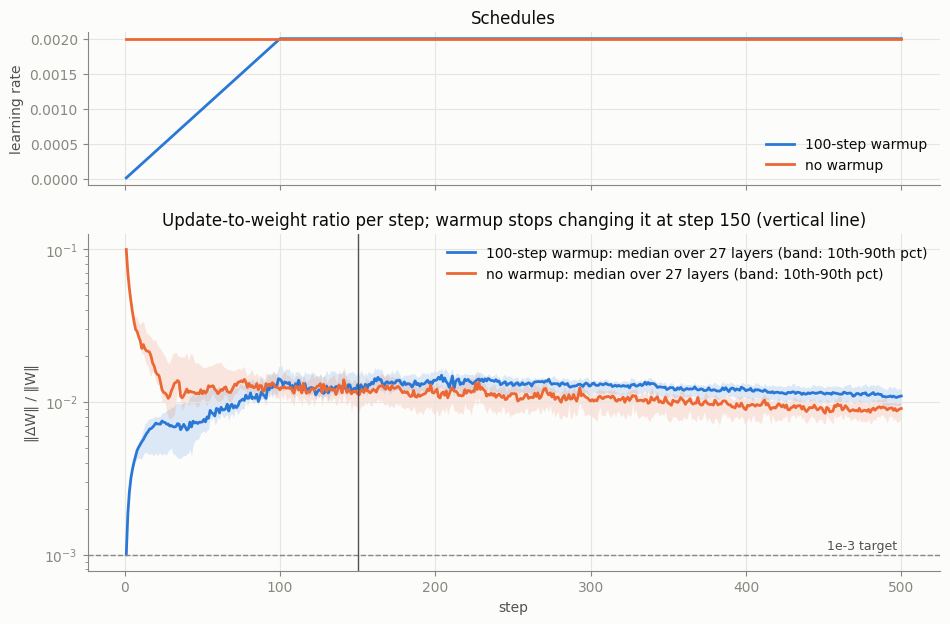

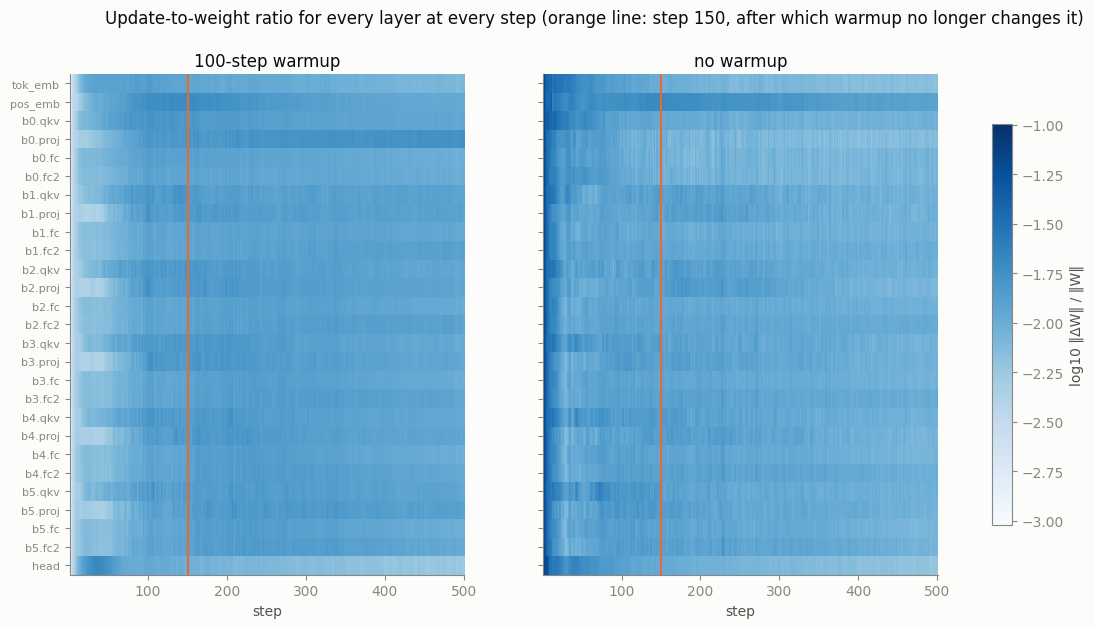

In [12]:
steps_ax = np.arange(1, WU_STEPS + 1)
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw=dict(height_ratios=[1, 2.2]))
ax[0].plot(steps_ax, wu["lr"], label="100-step warmup"); ax[0].plot(steps_ax, nw["lr"], label="no warmup")
ax[0].set(ylabel="learning rate", title="Schedules"); ax[0].legend()
for run, c, lab in ((wu, SERIES[0], "100-step warmup"), (nw, SERIES[1], "no warmup")):
    r = run["ratio"]
    ax[1].fill_between(steps_ax, np.percentile(r, 10, axis=1), np.percentile(r, 90, axis=1), color=c, alpha=0.15, lw=0)
    ax[1].plot(steps_ax, np.median(r, axis=1), color=c, label=f"{lab}: median over 27 layers (band: 10th-90th pct)")
ax[1].axhline(1e-3, color=MUTED, ls="--", lw=1); ax[1].text(WU_STEPS, 1.08e-3, "1e-3 target ", ha="right", color=INK2, fontsize=9)
ax[1].axvline(stop_median, color=INK2, lw=1)
ax[1].set(yscale="log", xlabel="step", ylabel="‖ΔW‖ / ‖W‖", title=f"Update-to-weight ratio per step; warmup stops changing it at step {stop_median} (vertical line)")
ax[1].legend(loc="upper right")
savefig(fig, "q3_update_ratio_median"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
lo, hi = np.log10(min(wu["ratio"].min(), nw["ratio"].min())), np.log10(max(wu["ratio"].max(), nw["ratio"].max()))
for a, run, ttl in ((ax[0], wu, "100-step warmup"), (ax[1], nw, "no warmup")):
    im = a.imshow(np.log10(run["ratio"].T), aspect="auto", cmap="Blues", vmin=lo, vmax=hi, interpolation="nearest",
                  extent=(0.5, WU_STEPS + 0.5, len(layers) - 0.5, -0.5))
    a.axvline(stop_median, color=SERIES[1], lw=1.5); a.set(title=ttl, xlabel="step"); a.grid(False)
ax[0].set_yticks(range(len(layers))); ax[0].set_yticklabels([short(n) for n in layers], fontsize=8)
fig.colorbar(im, ax=ax, label="log10 ‖ΔW‖ / ‖W‖", shrink=0.8)
fig.suptitle(f"Update-to-weight ratio for every layer at every step (orange line: step {stop_median}, after which warmup no longer changes it)")
savefig(fig, "q3_update_ratio_heatmap"); plt.show()

**Answer 3.** **Warmup stops changing the update-to-weight ratio at about step 150**, 50 steps after the learning-rate ramp ends at step 100.

* **Layer-median ratio:** the quotient `r_warmup / r_no-warmup` settles at step 150. Taken per layer, the median is step 154, the middle half of the 27 layers settle between steps 138 and 184, and the full range is 83 to 201. The warmup run's own ratio has already flattened by step 82, at 1.23e-2. What changes between steps 82 and 150 is the no-warmup run, which is still settling down from its violent start.
* **After that, warmup leaves a constant offset rather than none.** The warmup run's ratio stays about **1.22× higher** than the no-warmup run's for the rest of the run. Its weights are smaller, because the no-warmup run inflated its weights in the first few steps. The head (0.92×), position embeddings (0.87×) and `b0.proj` (2.27×) are the exceptions.
* **The first step is exactly the session's argument.** Without warmup, Adam's first step moves every weight by η = 2e-3 against weights initialised at 0.02, so every layer's ratio is **0.10** (the largest anywhere: 0.101, the head at step 1). That is 100× the 1e-3 guideline. With warmup the largest ratio anywhere is **0.021** (head, step 35), about 5× smaller, the same effect as the 19.2e-3 to 2.83e-3 in §9 of the notes.
* **Why early steps are big:** the ratio per unit of learning rate is 50 at step 1 in both runs, because every gradient agrees and Adam takes the full η step. It falls to 26 (warmup) or 13 (no warmup) by step 10, and to about 6 to 7 by step 50 as the gradients decorrelate. Warmup keeps the learning rate small through exactly the steps where the ratio per unit of learning rate is largest.
* **Loss:** at step 500 the warmup run has val loss **1.883** against **2.153** without warmup.
* **One caveat for V5:** after warmup the ratio sits at about 1e-2 here, 10× the session's 1e-3 target. That is a property of this tiny model (2e-3 learning rate, 0.02-scale weights) and a short run. A real run should log exactly this curve and treat a steady 1e-2 as a reason to lower the rate.

## 4. Cosine against WSD, both stopped at step 200

Both schedules are set up for a **300-step run** with a 30-step warmup (10%), and both end at 10% of peak:

* **cosine**: cosine from peak at step 30 to 10% of peak at step 300,
* **WSD**: flat at peak until step 240, then linear decay to 10% of peak over the last 60 steps (20%).

Then the run is stopped at step 200, as if the budget had been cut. Before comparing, each schedule's peak learning rate is tuned **on its own**: 4 peak values × 2 seeds, the same two data orders for both schedules. Each schedule's learning rate is chosen by its loss at step 300, the run that was planned. Validation loss is recorded every 50 steps.

In [13]:
SC_TOTAL, SC_STOP, SC_WARM = 300, 200, 30
SC_LRS, SC_SEEDS = [2e-3, 4e-3, 6e-3, 8e-3], [0, 1]
EVAL_EVERY = tuple(range(0, SC_TOTAL + 1, 50))
SCHED = {"cosine": lambda p: sched_cosine(p, SC_TOTAL, SC_WARM), "WSD": lambda p: sched_wsd(p, SC_TOTAL, SC_WARM)}
sc_runs = {}; t0 = time.time()
for name, mk in SCHED.items():
    for lr in SC_LRS:
        for sd in SC_SEEDS:
            sc_runs[(name, lr, sd)] = train(S10, SC_TOTAL, mk(lr), seed=sd, eval_at=EVAL_EVERY, diverge_loss=6.0,
                                            ckpt_at=SC_STOP if name == "WSD" else None)
print(f"{len(sc_runs)} runs in {time.time()-t0:.0f}s")

def mval(name, lr, s): return np.mean([val_or_nan(sc_runs[(name, lr, sd)], s) for sd in SC_SEEDS])
def sval(name, lr, s): return np.std([val_or_nan(sc_runs[(name, lr, sd)], s) for sd in SC_SEEDS])
print(f"\n{'peak lr':>8} | {'cosine @200':>11} {'cosine @300':>11} | {'WSD @200':>9} {'WSD @300':>9}   (val loss, mean of {len(SC_SEEDS)} seeds)")
for lr in SC_LRS:
    print(f"{lr:>8.1e} | {mval('cosine', lr, 200):>11.4f} {mval('cosine', lr, 300):>11.4f} | "
          f"{mval('WSD', lr, 200):>9.4f} {mval('WSD', lr, 300):>9.4f}")
tuned = {nm: min(SC_LRS, key=lambda lr: np.nan_to_num(mval(nm, lr, 300), nan=9)) for nm in SCHED}
best200 = {nm: min(SC_LRS, key=lambda lr: np.nan_to_num(mval(nm, lr, 200), nan=9)) for nm in SCHED}
print()
for nm in SCHED:
    lr = tuned[nm]
    print(f"{nm:6s}: tuned peak lr {lr:.0e} -> val @200 {mval(nm, lr, 200):.4f} ± {sval(nm, lr, 200):.4f}, "
          f"@300 {mval(nm, lr, 300):.4f} ± {sval(nm, lr, 300):.4f} | best lr if tuned for step 200 instead: "
          f"{best200[nm]:.0e} -> {mval(nm, best200[nm], 200):.4f}")

16 runs in 1159s

 peak lr | cosine @200 cosine @300 |  WSD @200  WSD @300   (val loss, mean of 2 seeds)
 2.0e-03 |      2.2864      2.1719 |    2.2748    2.0405
 4.0e-03 |      2.2408      2.0815 |    2.2343    1.9965
 6.0e-03 |      2.2388      2.0599 |    2.2361    2.0057
 8.0e-03 |      2.4861      2.4295 |    2.5179    2.4615

cosine: tuned peak lr 6e-03 -> val @200 2.2388 ± 0.0056, @300 2.0599 ± 0.0061 | best lr if tuned for step 200 instead: 6e-03 -> 2.2388
WSD   : tuned peak lr 4e-03 -> val @200 2.2343 ± 0.0219, @300 1.9965 ± 0.0016 | best lr if tuned for step 200 instead: 4e-03 -> 2.2343


WSD's flat phase means its step-200 weights are a **checkpoint**, not a finished model: the decay can still be applied from there. This is the property the session gives as the reason V5 chose WSD. To measure it, each WSD run is resumed from its saved step-200 state (weights, optimizer moments and data position) and decayed over 40 more steps, linearly to 10% of peak. For reference, a cosine schedule planned for **200** steps from the start, at its own tuned learning rate, shows what a deliberately short run achieves.

In [14]:
COOL = 40
wsd_cool = {}
for sd in SC_SEEDS:
    ck = sc_runs[("WSD", tuned["WSD"], sd)]["ckpt"]
    wsd_cool[sd] = train(S10, SC_STOP + COOL, sched_wsd(tuned["WSD"], SC_STOP + COOL, SC_WARM, decay_start=SC_STOP),
                         seed=sd, resume=ck, eval_at=(SC_STOP + COOL,))
cos200 = {}
_i = SC_LRS.index(tuned["cosine"]); C200_LRS = SC_LRS[max(0, _i - 1): _i + 2]      # its tuned lr and both neighbours
for lr in C200_LRS:
    for sd in SC_SEEDS:
        cos200[(lr, sd)] = train(S10, SC_STOP, sched_cosine(lr, SC_STOP, SC_WARM), seed=sd, eval_at=(SC_STOP,), diverge_loss=6.0)
c200_lr = min(C200_LRS, key=lambda lr: np.mean([val_or_nan(cos200[(lr, s)], SC_STOP) for s in SC_SEEDS]))
c200 = [val_or_nan(cos200[(c200_lr, s)], SC_STOP) for s in SC_SEEDS]
cool = [wsd_cool[s]["val"][SC_STOP + COOL] for s in SC_SEEDS]

lr_c, lr_w = tuned["cosine"], tuned["WSD"]
paired = [val_or_nan(sc_runs[("WSD", lr_w, s)], 200) - val_or_nan(sc_runs[("cosine", lr_c, s)], 200) for s in SC_SEEDS]
summary = {
    "cosine (planned 300) stopped at 200": (mval("cosine", lr_c, 200), sval("cosine", lr_c, 200), lr_c),
    "WSD (planned 300) stopped at 200": (mval("WSD", lr_w, 200), sval("WSD", lr_w, 200), lr_w),
    "WSD checkpoint @200 + 40-step decay": (np.mean(cool), np.std(cool), lr_w),
    "cosine planned for 200 steps": (np.mean(c200), np.std(c200), c200_lr),
    "cosine run to 300": (mval("cosine", lr_c, 300), sval("cosine", lr_c, 300), lr_c),
    "WSD run to 300": (mval("WSD", lr_w, 300), sval("WSD", lr_w, 300), lr_w),
}
print(f"{'model':40s} {'val loss':>9} {'± seed sd':>10} {'peak lr':>8}")
for k, (m_, s_, l_) in summary.items(): print(f"{k:40s} {m_:>9.4f} {s_:>10.4f} {l_:>8.0e}")
print(f"\nat step 200, WSD minus cosine, per seed (same data order): {', '.join(f'{d:+.4f}' for d in paired)}")
RESULTS["q4"] = dict(lrs=SC_LRS, tuned=tuned, best_at_200=best200, summary={k: list(v) for k, v in summary.items()},
                     paired_wsd_minus_cos_at_200=paired,
                     grid={nm: {str(lr): [mval(nm, lr, 200), mval(nm, lr, 300)] for lr in SC_LRS} for nm in SCHED})

model                                     val loss  ± seed sd  peak lr
cosine (planned 300) stopped at 200         2.2388     0.0056    6e-03
WSD (planned 300) stopped at 200            2.2343     0.0219    4e-03
WSD checkpoint @200 + 40-step decay         2.0928     0.0021    4e-03
cosine planned for 200 steps                2.2884     0.0142    6e-03
cosine run to 300                           2.0599     0.0061    6e-03
WSD run to 300                              1.9965     0.0016    4e-03

at step 200, WSD minus cosine, per seed (same data order): +0.0118, -0.0208


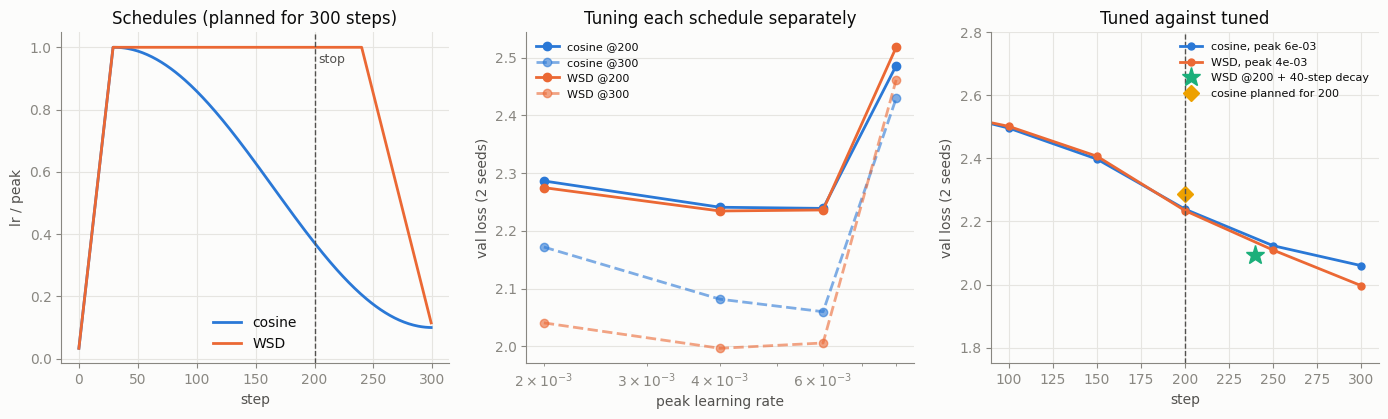

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
xs = np.arange(SC_TOTAL)
for i, nm in enumerate(SCHED):
    ax[0].plot(xs, [SCHED[nm](1.0)(s) for s in xs], color=SERIES[i], label=nm)
ax[0].axvline(SC_STOP, color=INK2, lw=1, ls="--"); ax[0].text(SC_STOP + 3, 0.95, "stop", color=INK2, fontsize=9)
ax[0].set(xlabel="step", ylabel="lr / peak", title="Schedules (planned for 300 steps)"); ax[0].legend()
for i, nm in enumerate(SCHED):
    ax[1].plot(SC_LRS, [mval(nm, l, 200) for l in SC_LRS], marker="o", color=SERIES[i], label=f"{nm} @200")
    ax[1].plot(SC_LRS, [mval(nm, l, 300) for l in SC_LRS], marker="o", ls="--", color=SERIES[i], alpha=0.6, label=f"{nm} @300")
ax[1].set(xscale="log", xlabel="peak learning rate", ylabel=f"val loss ({len(SC_SEEDS)} seeds)", title="Tuning each schedule separately"); ax[1].legend(fontsize=8)
ev = sorted(EVAL_EVERY)
for i, (nm, lr) in enumerate(tuned.items()):
    ax[2].plot(ev, [mval(nm, lr, s) for s in ev], marker="o", ms=5, color=SERIES[i], label=f"{nm}, peak {lr:.0e}")
ax[2].plot([SC_STOP + COOL], [np.mean(cool)], marker="*", ms=14, color=SERIES[2], ls="none", label="WSD @200 + 40-step decay")
ax[2].plot([SC_STOP], [np.mean(c200)], marker="D", ms=8, color=SERIES[3], ls="none", label="cosine planned for 200")
ax[2].axvline(SC_STOP, color=INK2, lw=1, ls="--")
ax[2].set(xlabel="step", ylabel=f"val loss ({len(SC_SEEDS)} seeds)", title="Tuned against tuned", ylim=(1.75, 2.8), xlim=(90, 310)); ax[2].legend(fontsize=8)
savefig(fig, "q4_cosine_vs_wsd"); plt.show()

**Answer 4.** Tuned separately, the best peak learning rates are **6e-3 for cosine and 4e-3 for WSD**. Both lie inside the grid, and 8e-3 breaks both schedules.

| model (validation loss, mean of 2 seeds) | loss |
|---|---|
| **cosine (planned for 300) stopped at step 200** | **2.2388** ± 0.006 |
| **WSD (planned for 300) stopped at step 200** | **2.2343** ± 0.022 |
| WSD step-200 checkpoint + 40 steps of decay | 2.0928 ± 0.002 |
| cosine planned for 200 steps from the start (tuned) | 2.2884 ± 0.014 |
| cosine run to 300 | 2.0599 |
| WSD run to 300 | 1.9965 |

* **At step 200 the two are tied.** The 0.005 difference is far inside the seed noise, and the paired per-seed differences go both ways (+0.012, −0.021).
* **I would keep the WSD model.** Its step-200 weights are a checkpoint on the flat part of the schedule, so they can still be finished. Forty more steps of decay take them to **2.093**, which is 0.146 better than the cosine model and better than a cosine run planned for 200 steps. The cosine model has already spent most of its decay: its learning rate at step 200 is 37% of peak on a curve tied to a 300-step plan, so it has nowhere sensible to continue. Even with no extra steps allowed, the losses are equal, and WSD keeps the option of continuing. That is the session's reason for choosing it for V5. WSD also wins the full run, 1.997 against 2.060.
* **One result went against the session notes.** The notes say a cosine run stopped early is worse than one planned for that length. Here the planned 200-step cosine (2.288) is *worse* than the 300-step cosine stopped at 200 (2.239). This model is still far from converged (loss falling about 0.1 per 50 steps), and in that regime progress follows the total learning rate spent. The shorter cosine spends less of it. The claim probably needs a run that is closer to convergence, which 200 steps of this model is not.

## 5. Learning-rate sweep at widths 256, 512 and 1,024

Standard parameterization (`std = 1/sqrt(fan_in)`, one learning rate for every weight), 2 layers, head size 64 (so 4, 8 and 16 heads), AdamW `β = (0.9, 0.95)`, weight decay 0.1, 150 steps with a 15-step warmup and cosine decay to 10%. To fit width 1,024 on this throttling laptop GPU the sweep uses **context 64** (batch 32 × 64 = 2,048 characters per step); validation uses the same 65,536 characters as everywhere else, cut into 64-long rows.

Eight learning rates a factor of 2 apart (1.25e-4 to 1.6e-2) are run at every width with seed 0, from the smallest upwards; once two consecutive points are more than 0.1 above the best so far, the larger rates are skipped, since they only get worse. A second seed is then run at the best grid point and its two neighbours, which is where the minimum is located: a parabola is fitted to the two-seed mean validation loss against `log2(lr)` through those three points. A run whose training loss is not finite or above 5 after step 50 is counted as diverged.

In [16]:
WIDTHS = [256, 512, 1024]
SW_LRS = [1.25e-4 * 2 ** k for k in range(8)]          # 1.25e-4 ... 1.6e-2
SW_STEPS, SW_WARM, SW_T = 150, 15, 64
lx = np.log2(SW_LRS)
sw_runs = {}

def sw_cfg(C): return dict(C=C, L=2, H=C // 64, init="sp")
def sw_run(C, lr, sd):
    sw_runs[(C, lr, sd)] = train(sw_cfg(C), SW_STEPS, sched_cosine(lr, SW_STEPS, SW_WARM), seed=sd,
                                 eval_at=(SW_STEPS,), diverge_loss=5.0, T_ctx=SW_T)
def sw_v(C, lr, sd): return sw_runs[(C, lr, sd)]["val"].get(SW_STEPS, np.nan) if (C, lr, sd) in sw_runs else np.nan

def parabola_min(i3, ys3):
    a, b, c = np.polyfit(lx[i3], ys3, 2)
    if a <= 0: k = int(np.argmin(ys3)); return SW_LRS[i3[k]], float(ys3[k])
    x0 = float(np.clip(-b / (2 * a), lx[i3[0]], lx[i3[-1]])); return 2 ** x0, float(np.polyval([a, b, c], x0))

minima = {}
for C in WIDTHS:
    n_par = sum(p.numel() for p in GPT(**sw_cfg(C)).parameters()); t0 = time.time()
    best = np.inf; above = 0
    for lr in SW_LRS:
        sw_run(C, lr, 0); v = sw_v(C, lr, 0)
        best = min(best, v) if np.isfinite(v) else best
        above = above + 1 if (not np.isfinite(v) or v > best + 0.1) else 0
        if above == 2: break
    y0 = np.array([sw_v(C, lr, 0) for lr in SW_LRS])
    ib = int(np.nanargmin(y0)); ic = min(max(ib, 1), len(SW_LRS) - 2); i3 = [ic - 1, ic, ic + 1]
    for i in i3:
        if (C, SW_LRS[i], 0) not in sw_runs: sw_run(C, SW_LRS[i], 0)
        sw_run(C, SW_LRS[i], 1)
    y3 = {sd: np.array([sw_v(C, SW_LRS[i], sd) for i in i3]) for sd in (0, 1)}
    lr_star, l_star = parabola_min(i3, (y3[0] + y3[1]) / 2)
    minima[C] = dict(lr=lr_star, loss=l_star, grid_best=SW_LRS[ib], fit_points=[SW_LRS[i] for i in i3],
                     per_seed=[parabola_min(i3, y3[sd])[0] for sd in (0, 1)],
                     seed_gap=float(np.mean(np.abs(y3[0] - y3[1]))))
    print(f"width {C:>5}: {n_par/1e6:5.1f}M weights, {sum(k[0] == C for k in sw_runs)} runs in {time.time()-t0:.0f}s")

print(f"\n{'lr':>9} | " + " | ".join(f"{'width ' + str(C):>19}" for C in WIDTHS) + "   (val loss at step 150: seed 0 / seed 1; '-' = skipped)")
for lr in SW_LRS:
    cell = lambda C: (f"{sw_v(C, lr, 0):.4f}" if np.isfinite(sw_v(C, lr, 0)) else
                      "diverged" if (C, lr, 0) in sw_runs else "-") + \
                     (f" / {sw_v(C, lr, 1):.4f}" if np.isfinite(sw_v(C, lr, 1)) else "         ")
    print(f"{lr:>9.2e} | " + " | ".join(f"{cell(C):>19}" for C in WIDTHS))
print()
for C in WIDTHS:
    m = minima[C]
    print(f"width {C:>5}: minimum at lr {m['lr']:.2e} (fitted), loss {m['loss']:.4f}; best grid point {m['grid_best']:.2e}; "
          f"per-seed fits {m['per_seed'][0]:.2e}, {m['per_seed'][1]:.2e}; mean seed-to-seed gap {m['seed_gap']:.4f}")

width   256:   1.6M weights, 11 runs in 111s
width   512:   6.4M weights, 11 runs in 359s
width  1024:  25.5M weights, 10 runs in 1141s

       lr |           width 256 |           width 512 |          width 1024   (val loss at step 150: seed 0 / seed 1; '-' = skipped)
 1.25e-04 |     2.6862          |     2.5020          |     2.4170         
 2.50e-04 |     2.5496          |     2.4192          |     2.2816         
 5.00e-04 |     2.4604          |     2.2987          |     2.1584 / 2.1508
 1.00e-03 |     2.3365          |     2.1823 / 2.1640 |     2.1068 / 2.1028
 2.00e-03 |     2.2045 / 2.2107 |     2.1198 / 2.1086 |     2.1316 / 2.1581
 4.00e-03 |     2.1380 / 2.1181 |     2.1613 / 2.1242 |     2.4749         
 8.00e-03 |     2.1403 / 2.1519 |     2.4853          |     2.5945         
 1.60e-02 |     2.4719          |     2.5831          |          -         

width   256: minimum at lr 4.97e-03 (fitted), loss 2.1232; best grid point 4.00e-03; per-seed fits 5.53e-03, 4.70e-03; me

**Extrapolating to width 4,096.** A straight line through the three minima in log-log space gives `lr* ∝ width^slope`. The standard-parameterization rule in §12 of the session is a slope of −1 (halve the rate per doubling of width). The spread comes from refitting the line on every combination of per-seed minima.

In [17]:
import itertools
lw = np.log2(WIDTHS); lm = np.log2([minima[C]["lr"] for C in WIDTHS])
slope, icpt = np.polyfit(lw, lm, 1)
pred_4096 = 2 ** (icpt + slope * 12)
alt = []
for combo in itertools.product(*[minima[C]["per_seed"] for C in WIDTHS]):
    s_, i_ = np.polyfit(lw, np.log2(combo), 1); alt.append(2 ** (i_ + s_ * 12))
inv_width = minima[1024]["lr"] / 4                  # the -1 rule applied from width 1,024
print(f"fitted slope {slope:+.2f} (standard-parameterization rule: -1)")
print(f"fitted line at width 4,096: {pred_4096:.2e}  (range over per-seed refits {min(alt):.2e} to {max(alt):.2e})")
print(f"1/width rule from the width-1,024 minimum: {inv_width:.2e}")
RESULTS["q5"] = dict(widths=WIDTHS, lrs=SW_LRS, minima={str(C): minima[C] for C in WIDTHS}, slope=slope,
                     pred_4096_fit=pred_4096, pred_4096_range=[min(alt), max(alt)], pred_4096_inv_width=inv_width,
                     grid={str(C): [[sw_v(C, lr, 0), sw_v(C, lr, 1)] for lr in SW_LRS] for C in WIDTHS})

fitted slope -1.13 (standard-parameterization rule: -1)
fitted line at width 4,096: 2.16e-04  (range over per-seed refits 1.68e-04 to 2.76e-04)
1/width rule from the width-1,024 minimum: 2.60e-04


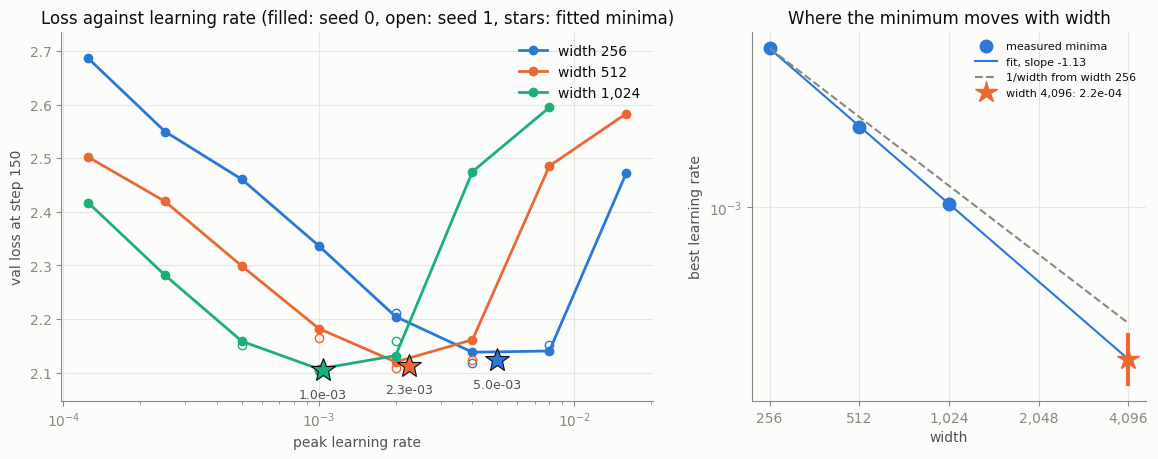

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
for i, C in enumerate(WIDTHS):
    ys = [sw_v(C, lr, 0) for lr in SW_LRS]
    ax[0].plot(SW_LRS, ys, marker="o", ms=6, color=SERIES[i], label=f"width {C:,}")
    fp = minima[C]["fit_points"]
    ax[0].plot(fp, [sw_v(C, lr, 1) for lr in fp], marker="o", ms=6, mfc="none", color=SERIES[i], ls="none")
    ax[0].plot([minima[C]["lr"]], [minima[C]["loss"]], marker="*", ms=18, color=SERIES[i], mec=INK, mew=0.8, ls="none")
    ax[0].annotate(f"{minima[C]['lr']:.1e}", (minima[C]["lr"], minima[C]["loss"]), textcoords="offset points",
                   xytext=(0, -20), ha="center", color=INK2, fontsize=9)
finite = [sw_v(C, lr, 0) for C in WIDTHS for lr in SW_LRS if np.isfinite(sw_v(C, lr, 0))]
ax[0].set(xscale="log", xlabel="peak learning rate", ylabel=f"val loss at step {SW_STEPS}",
          title="Loss against learning rate (filled: seed 0, open: seed 1, stars: fitted minima)",
          ylim=(min(finite) - 0.06, min(max(finite), min(finite) + 1.0) + 0.05))
ax[0].legend()
ww = np.array([256, 512, 1024, 2048, 4096])
ax[1].plot(WIDTHS, [minima[C]["lr"] for C in WIDTHS], "o", ms=9, color=SERIES[0], label="measured minima")
ax[1].plot(ww, 2 ** (icpt + slope * np.log2(ww)), color=SERIES[0], lw=1.5, label=f"fit, slope {slope:+.2f}")
ax[1].plot(ww, minima[256]["lr"] * 256 / ww, color=MUTED, ls="--", lw=1.5, label="1/width from width 256")
ax[1].plot([4096, 4096], [min(alt), max(alt)], color=SERIES[1], lw=3)
ax[1].plot([4096], [pred_4096], marker="*", ms=16, color=SERIES[1], ls="none", label=f"width 4,096: {pred_4096:.1e}")
ax[1].set(xscale="log", yscale="log", xlabel="width", ylabel="best learning rate", title="Where the minimum moves with width")
ax[1].set_xticks(ww); ax[1].set_xticklabels([f"{w:,}" for w in ww]); ax[1].minorticks_off(); ax[1].legend(fontsize=8)
savefig(fig, "q5_lr_sweep_widths"); plt.show()

**Answer 5.** The fitted minima are **5.0e-3 at width 256, 2.3e-3 at width 512 and 1.0e-3 at width 1,024**: the best rate falls by a factor of about 2.2 per doubling of width. The log-log slope is **−1.13**, close to the −1 that §12 of the notes predicts for the standard parameterization. Per-seed fits agree to within ±12% at every width.

**Value for width 4,096: 2e-4.** The fitted line gives 2.2e-4, and refitting on every combination of per-seed minima gives 1.7e-4 to 2.8e-4. Applying the 1/width rule to the width-1,024 minimum gives 2.6e-4. I round towards the lower end for two reasons. First, each curve is much steeper on the high side: at width 1,024, 4× above the minimum costs 0.37 in loss, while 4× below costs 0.18. Second, the trend is slightly steeper than −1. The value happens to match the 1.9e-4 in the session's table for 4,096.

**Confidence: moderate on the scale, low on the exact number.** I'd put about 70% on the true optimum, *for this recipe*, lying between 1.5e-4 and 3e-4.
* It is an extrapolation 4× beyond the widest model measured, from three points, two seeds near each minimum and a factor-of-2 grid.
* The proxy differs from a real 4,096-wide model: 2 layers, context 64 and 150 steps. Short runs favour larger rates, so a long run's optimum is likely somewhat lower still.

Before committing a real run to it, I would run a three-point check at width 4,096 (1e-4, 2e-4, 4e-4), or move to muP, where a sweep at width 256 transfers directly.

## Summary

| # | Question | Result |
|---|---|---|
| 1 | Adam by hand vs PyTorch | All of `m`, `v`, `m̂`, `v̂`, step and `w` agree exactly in fp64 (largest gap 4.8e-17) and to 7 or more decimals in fp32. Steps are −0.001000, −0.000988, −0.000994, −0.000990, −0.000996, giving w = 0.995031. |
| 2 | Bias correction off | The uncorrected step is 3.16× at step 1, peaks at 6.57× at step 12, and is still 6.24× at step 20. It stops mattering after **~3,900 steps** at β2 = 0.999 (within 1%), or after 76 steps at β2 = 0.95. Tuned against tuned at 300 steps the loss gap is 0.067 (2.185 vs 2.253); untuned it looks like 0.36. |
| 3 | Update-to-weight ratio | Warmup stops changing it at **step ~150** (layer median 154, middle half 138 to 184). The largest ratio is 0.10 without warmup and 0.021 with it. Afterwards the warmup run stays 1.22× higher. |
| 4 | Cosine vs WSD, stopped at 200 | **2.2388 vs 2.2343**, a tie within seed noise. **Keep WSD**: its checkpoint decays to 2.093 in 40 steps, and it also wins at 300 (1.997 vs 2.060). |
| 5 | LR sweep by width | Minima at **5.0e-3, 2.3e-3, 1.0e-3** (slope −1.13). **Use 2e-4 at 4,096**, with moderate confidence on the scale (≈70% within 1.5e-4 to 3e-4). |

In [19]:
def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not math.isfinite(float(o)) else float(o)
    if isinstance(o, np.integer): return int(o)
    return o
json.dump(to_jsonable(RESULTS), open("results.json", "w"), indent=1)
np.savez_compressed("logs/update_ratio.npz", layers=np.array(layers), warmup=wu["ratio"], no_warmup=nw["ratio"])
print(f"results.json and logs/update_ratio.npz written; whole notebook ran in {(time.time()-T_START)/60:.1f} min on {dev}")

results.json and logs/update_ratio.npz written; whole notebook ran in 79.5 min on cuda
